# Monte Carlo
*Drag projectiles that stop when they land*

A batch of projectiles flies until each one lands or leaves the field. Every projectile has its own speed and angle and
feels linear drag, so they stop at different steps. This page writes one projectile's step and the stop rule, and runs the
batch until every sample has ended. Composing the live samples into a compacted, replayed loop is a different job, on
[eagle's Monte Carlo tutorial](https://amasat01.github.io/eagle/content/userguide/tutorials/21_monte_carlo_early_termination.html).

**Time:** ~5 min &middot; **Runs on:** CPU (a GPU runs a larger batch) &middot;
**You need:** hawk, eagle, NumPy and matplotlib; read first: [hawk in your domain](../vocabulary)

**Colab or Kaggle:** run this first cell (it installs the packages and downloads the helper files this notebook uses). Elsewhere it only checks the imports.

In [1]:
# Colab setup, generated by python -m raptor_docs.nb colab_setup (do not edit).
import os

try:
    import google.colab  # noqa: F401
    HOSTED = True  # a Colab runtime
except ImportError:
    HOSTED = "KAGGLE_KERNEL_RUN_TYPE" in os.environ  # a Kaggle kernel

if HOSTED:
    import importlib.metadata, pathlib, re, shutil, subprocess, sys, urllib.request

    gpu = bool(shutil.which("nvidia-smi")) and subprocess.run(["nvidia-smi", "-L"], capture_output=True).returncode == 0
    extra = ""
    if gpu:
        # the CUDA major the runtime already has: a CuPy that is installed, else torch's, else the driver's
        major = None
        for m in ("13", "12"):
            try:
                importlib.metadata.version(f"cupy-cuda{m}x")
                major = m
                break
            except importlib.metadata.PackageNotFoundError:
                pass
        if major is None:
            try:
                import torch
                major = "13" if str(torch.version.cuda).startswith("13") else None
            except ImportError:
                pass
        if major is None:
            smi = re.search(r"CUDA Version: (\d+)", subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
            major = "13" if smi and int(smi.group(1)) >= 13 else "12"
        extra = f"[cuda{major}]"
        print(f"GPU found: installing the {extra} extras to match this runtime.")
    pre = ["--pre"] if os.environ.get("RAPTOR_PRE") else []  # optional: test a release candidate
    ref = os.environ.get("RAPTOR_REF", "main")  # optional: fetch the helper files from this git ref
    if pre or "RAPTOR_REF" in os.environ:
        print(f"Pre-release test: installing with --pre, helper files from {ref}.")
    # our packages with --upgrade, so a runtime that kept an older release gets the current one
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", *pre, f"raptor-eagle{extra}", f"raptor-hawk{extra}"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "matplotlib"])
    base = os.environ.get("RAPTOR_RAW_BASE", "https://raw.githubusercontent.com")  # optional: a local mirror
    top = os.environ.get("RAPTOR_WORKDIR") or ("/kaggle/working" if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "/content")
    root = pathlib.Path(top) / "hawk"
    for rel in (
        "docs/content/_shared/anim.py",
        "docs/content/_shared/nb_helpers.py",
        "docs/content/_shared/themed_figure.py",
    ):
        (root / rel).parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f"{base}/amasat01/hawk/{ref}/{rel}", root / rel)
    (root / "docs/content/vocabulary").mkdir(parents=True, exist_ok=True)
    os.chdir(root / "docs/content/vocabulary")
    if not gpu:
        print("Running on the CPU (no GPU in this runtime). For a GPU: " + ("Settings → Accelerator → GPU T4 x2." if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "Runtime → Change runtime type → T4 GPU."))

try:
    import eagle, hawk, matplotlib  # noqa: F401
except ImportError as err:
    raise ImportError(
        "eagle, hawk, matplotlib not found. Install with `pip install matplotlib raptor-eagle raptor-hawk`. For a GPU, add [cuda12] (or [cuda13]) to raptor-eagle and raptor-hawk."
    ) from err

In [2]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "_shared"))
from nb_helpers import gpu_available, on_device, plot_style, show, to_numpy, xp
plot_style()

## The projectile's words

Say the vocabulary first. A projectile has a position `pos` and a velocity `vel`, both written by each step; the drag `drag`, gravity `g`, time step `dt` and field length `xmax` are the same for all; and a `terminated` flag marks the ones that have landed or left. Declare them once as a `KernelKind`; the step below is written in these names.

In [3]:
from hawk import Mutable, Param, Terminated, Vector
from hawk.ext import KernelKind


class Projectile(KernelKind, slug="projectile"):
    drag: Param
    g: Param
    dt: Param
    xmax: Param
    terminated: Terminated
    pos: Mutable[Vector[2]]
    vel: Mutable[Vector[2]]

Projectile

__main__.Projectile

## One sample's step

Units are SI: metres, seconds, metres per second. A sample's state is a position and a velocity, two `Vector[2]`. The
step is a semi-implicit (symplectic) Euler update with linear drag `drag`: the velocity first, then the position from the
**new** velocity. It is first order in `dt`; the check below confirms that.

Reading `pos` before writing it gives the value at the start of the step, so `before = pos` keeps it. Two things end a
sample, and both are written once, in `terminated`: it is below the ground (the landing), or past `xmax`. A landing is seen
one step late, so the kernel also interpolates between the start and the end of the step to the point where `y` crosses
zero and writes it to `x_land`. The interpolation removes the one-step-late bias (up to `dt * |vy|`, about 0.6 m). A sample that is flagged stops stepping, and its outputs stay as they were.

In [4]:
import numpy as np
import eagle
import hawk
import hawk.math as m
from hawk import Mutable, Param, Scalar, Terminated, Vector


@Projectile
def fly(drag, g, dt, xmax, terminated, pos, vel,
        x_land: Mutable[Scalar]):
    before = pos
    vel = vel + dt * (m.vec(0.0, -g) - drag * vel)
    pos = before + dt * vel                                   # the new velocity: symplectic Euler
    y0, y1 = before.components[1], pos.components[1]
    x_hit = before.components[0] + (y0 / (y0 - y1)) * (pos.components[0] - before.components[0])
    x_land = m.where(y1 < 0.0, x_hit, x_land)                 # where the path crossed y = 0
    terminated = m.lor(y1 < 0.0, pos.components[0] > xmax)    # landed, or left the field


fly

<Kernel fly slots=10>

## Fly the batch to the end

`eagle.simulate(kernel, max_steps=..., **planes)` runs the kernel until every sample has set `terminated`, or until
`max_steps`. Planes go in by name and are advanced in place, so `fly_batch` hands over copies; the plain numbers are the parameters. Speeds and angles are drawn at random, so a flat
shot lands within a few steps and a lob takes many. `x_land` starts as NaN, so a projectile that leaves the field keeps NaN.

In [5]:
G, DRAG, XMAX, DT = 9.81, 0.1, 40.0, 0.02       # m/s^2, 1/s, m, s


def draw(n, seed=3):
    rng = np.random.default_rng(seed)
    speed, angle = rng.uniform(8.0, 30.0, n), rng.uniform(0.15, 1.35, n)
    return np.stack([np.zeros(n), np.zeros(n)]), np.stack([speed * np.cos(angle), speed * np.sin(angle)])


def fly_batch(pos, vel, dt=DT, xmax=XMAX):
    return eagle.simulate(fly, pos=pos.copy(), vel=vel.copy(), x_land=np.full(pos.shape[1], np.nan),
                          drag=DRAG, g=G, dt=dt, xmax=xmax, max_steps=20000)


n = 512
pos0, vel0 = draw(n)
batch = fly_batch(pos0, vel0)
landed = ~np.isnan(batch.x_land)
print(f"{batch.status}: {int(batch.finished.sum())} of {n} ended; {int(landed.sum())} landed, {int((~landed).sum())} left the field")

finished: 512 of 512 ended; 403 landed, 109 left the field


## Check it against the exact solution

Linear drag has a closed form: `x(t) = vx0/k (1 - exp(-k t))` and `y(t) = (vy0 + g/k)/k (1 - exp(-k t)) - g t / k`. Solving
`y(t) = 0` gives the exact landing point. Run a few samples with `dt`, `dt/2` and `dt/4` and compare `x_land`. What is
left after the interpolation comes from the first-order step, and that is what this check measures: a first-order scheme
halves its error each time. (An exact linear-drag update would leave only the interpolation's own error, under a millimetre.)

In [6]:
def exact_landing(vel):
    out = []
    for vx, vy in vel.T:
        y = lambda t: (vy + G / DRAG) / DRAG * (1 - np.exp(-DRAG * t)) - G * t / DRAG
        lo, hi = 1e-9, 4 * vy / G                      # y > 0 at lo, y < 0 at hi
        for _ in range(200):
            mid = 0.5 * (lo + hi)
            lo, hi = (mid, hi) if y(mid) > 0 else (lo, mid)
        out.append(vx / DRAG * (1 - np.exp(-DRAG * 0.5 * (lo + hi))))
    return np.array(out)


speed, angle = np.array([14.0, 20.0, 26.0]), np.array([0.7, 1.0, 1.2])
vel_check = np.stack([speed * np.cos(angle), speed * np.sin(angle)])
want = exact_landing(vel_check)
errors = [np.abs(fly_batch(np.zeros((2, 3)), vel_check, dt=dt, xmax=1e9).x_land - want).max() for dt in (0.02, 0.01, 0.005)]
ratios = [errors[i] / errors[i + 1] for i in range(2)]
assert all(1.8 < r < 2.2 for r in ratios), ratios
print("largest landing-point error for dt = 0.02, 0.01, 0.005 (m):", [f"{e:.3f}" for e in errors])
print("ratios:", [f"{r:.2f}" for r in ratios], "(about 2: first order)")

largest landing-point error for dt = 0.02, 0.01, 0.005 (m): ['0.225', '0.113', '0.056']
ratios: ['2.00', '2.00'] (about 2: first order)


## Watch it end

`eagle.simulate` runs the whole loop for you. To draw the paths we step the same kernel by hand: `hawk.artifact.build` and
`hawk.load` give the compiled step, and `hawk.run` advances every sample that is not yet flagged by one step. We keep the
first 48 paths. The final state is the same as the batch run above.

In [7]:
import pathlib, tempfile
import hawk.artifact

work_dir = pathlib.Path(tempfile.mkdtemp())
hawk.artifact.build(fly, work_dir, targets=("host",))
one_step = hawk.load(work_dir, "fly")

SHOWN = 48
pos, vel = pos0.copy(), vel0.copy()
done, x_land = np.zeros(n, dtype=bool), np.full(n, np.nan)
path, ended = [pos[:, :SHOWN].copy()], [done[:SHOWN].copy()]
while not done.all():
    hawk.run(one_step, pos=pos, vel=vel, x_land=x_land, terminated=done, drag=DRAG, g=G, dt=DT, xmax=XMAX)
    path.append(pos[:, :SHOWN].copy())
    ended.append(done[:SHOWN].copy())

same = np.array_equal(pos, batch.pos) and np.array_equal(x_land, batch.x_land, equal_nan=True)
assert same
print(f"every sample ended within {len(path) - 1} steps; same final state as the batch run: {same}")

every sample ended within 260 steps; same final state as the batch run: True


The paths, and where the projectiles that landed came down. The dashed line is the edge of the field:


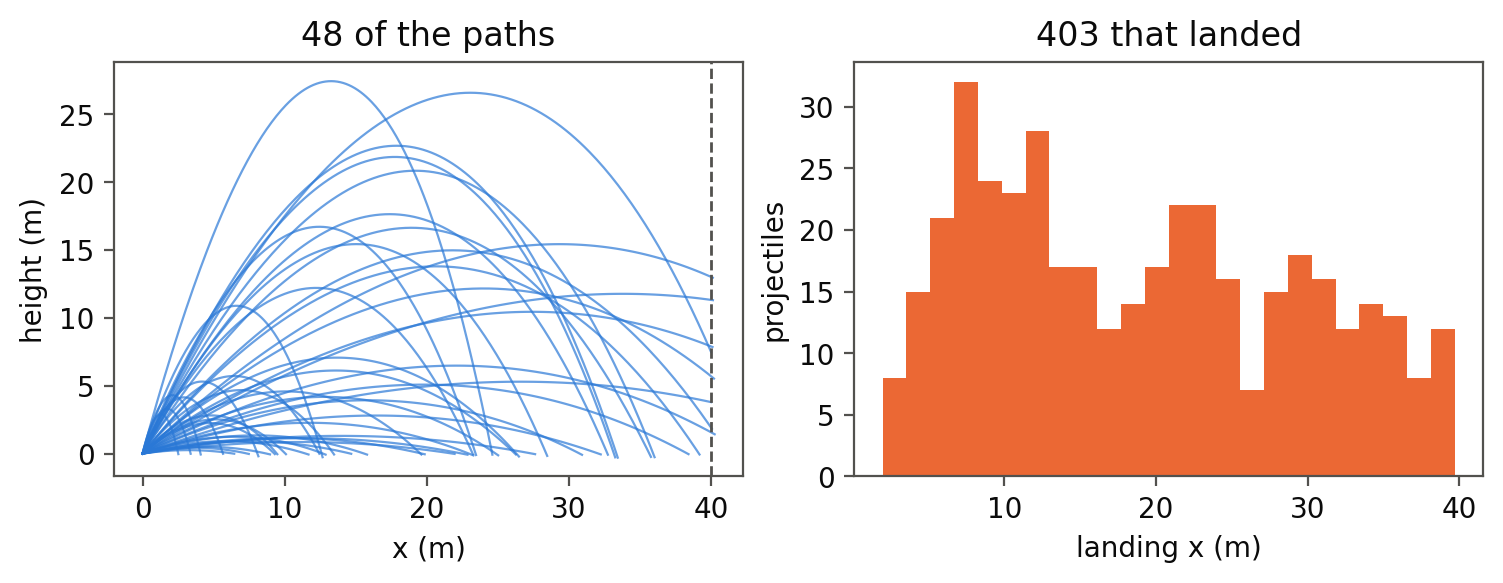
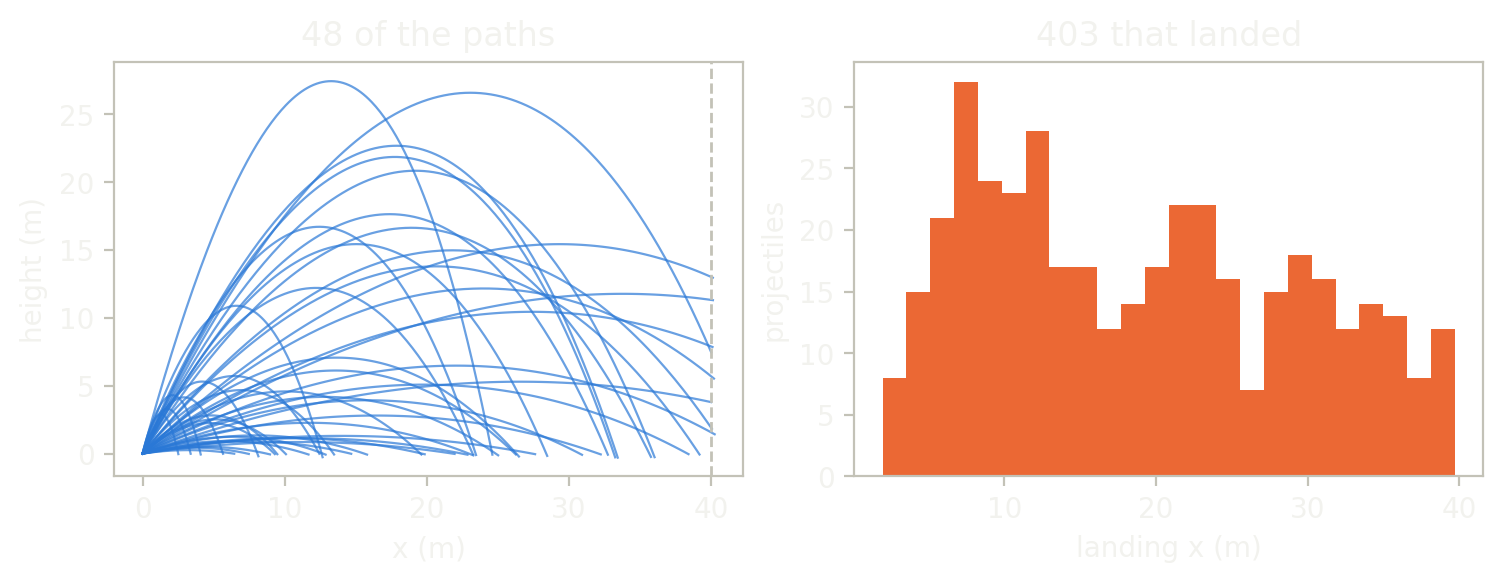

In [8]:
import matplotlib.pyplot as plt

trace = np.array(path)                       # (step, 2, SHOWN)
fig, (left, right) = plt.subplots(1, 2, figsize=(7.4, 2.8), constrained_layout=True)
for j in range(SHOWN):
    stop = int(np.argmax([e[j] for e in ended]))
    left.plot(trace[: stop + 1, 0, j], trace[: stop + 1, 1, j], lw=0.8, alpha=0.7, color="#2a78d6")
left.axvline(XMAX, ls="--", lw=1.0, color="#898781")
left.set_xlabel("x (m)"); left.set_ylabel("height (m)"); left.set_title("48 of the paths")
right.hist(batch.x_land[landed], bins=24, color="#eb6834")
right.set_xlabel("landing x (m)"); right.set_ylabel("projectiles"); right.set_title(f"{int(landed.sum())} that landed")
show()

## A bigger batch, when a GPU is there

The same kernel, with the planes handed over as device arrays, runs on the GPU and ends every sample there. The first 512
samples must end as the host run ends them, within hawk's few-ULP contract between devices (not bit for bit: a fused
multiply-add rounds differently).

In [9]:
if gpu_available():
    big = 200_000
    pos_big, vel_big = draw(big)
    got = eagle.simulate(fly, pos=xp.asarray(pos_big), vel=xp.asarray(vel_big), x_land=xp.full(big, xp.nan),
                         drag=DRAG, g=G, dt=DT, xmax=XMAX, max_steps=20000)
    assert on_device(got.x_land), "the result is a device array: the kernel ran on the GPU"
    host = fly_batch(pos_big[:, :512], vel_big[:, :512])
    # devices agree within hawk's few-ULP contract, not bit for bit (multiply-add fusion differs)
    first = to_numpy(got.x_land)[:512]
    assert np.array_equal(np.isnan(first), np.isnan(host.x_land))
    assert np.allclose(first, host.x_land, rtol=1e-9, equal_nan=True)
    print(f"{big} projectiles on the GPU: {int(got.finished.sum())} ended; the first 512 agree with the host run to 1e-9")
else:
    print("no GPU here; the batch stays at", n, "projectiles")

200000 projectiles on the GPU: 200000 ended; the first 512 agree with the host run to 1e-9


## The animation

The last cell writes the paths as a looping GIF, one for a light page and one for a dark page: a projectile is blue while
it flies, orange once it has landed and grey once it has left the field.

In [10]:
from anim import frame_of, write_anim
from themed_figure import DARK, LIGHT

pick = np.unique(np.linspace(0, len(path) - 1, 60).astype(int))
landed_shown = ~np.isnan(x_land[:SHOWN])


def render(theme, i):
    pal = LIGHT if theme == "light" else DARK
    fig = plt.figure(figsize=(5.0, 2.8), dpi=60, facecolor=pal["bg"])
    ax = fig.add_axes([0.14, 0.17, 0.83, 0.78], facecolor=pal["bg"])
    ax.set_xlim(0, XMAX + 4)
    ax.set_ylim(0, 1.05 * trace[:, 1].max())
    ax.set_xlabel("x (m)", color=pal["sub"], fontsize=8)
    ax.set_ylabel("height (m)", color=pal["sub"], fontsize=8)
    ax.tick_params(colors=pal["sub"], labelsize=7)
    for spine in ax.spines.values():
        spine.set_color(pal["rule"])
    ax.axvline(XMAX, ls="--", lw=1.0, color=pal["off"])
    for j in range(SHOWN):
        ax.plot(trace[: i + 1, 0, j], trace[: i + 1, 1, j], lw=0.7, alpha=0.6, color="#2a78d6")
    colours = ["#2a78d6" if not ended[i][j] else "#eb6834" if landed_shown[j] else pal["off"] for j in range(SHOWN)]
    ax.scatter(trace[i, 0], trace[i, 1], s=9, c=colours, zorder=3)
    ax.text(0.02, 0.92, f"{int((~np.array(ended[i])).sum())} of {SHOWN} still flying", transform=ax.transAxes,
            fontsize=8, color=pal["ink"])
    return frame_of(fig, pal["bg"])


for theme in ("light", "dark"):
    movie = [render(theme, i) for i in pick]
    for name, size in write_anim(movie, "monte_carlo_ensemble_" + theme).items():
        print(name, f"{size / 1e3:.0f} kB")

monte_carlo_ensemble_light.gif 654 kB


monte_carlo_ensemble_dark.gif 467 kB


```{image} ../../_static/anim/monte_carlo_ensemble_light.gif
:class: only-light
:alt: Projectile paths growing and ending one by one: blue while flying, orange once landed, grey once past the edge of the field
```
```{image} ../../_static/anim/monte_carlo_ensemble_dark.gif
:class: only-dark
:alt: Projectile paths growing and ending one by one: blue while flying, orange once landed, grey once past the edge of the field
```

## What just happened

- `pos` and `vel` are `Vector[2]` states; the step reads each before writing it, and the second line uses the new velocity.
- `terminated` is the one line that says when a sample is done. A flagged sample stops stepping and keeps its outputs.
- `x_land` is a per-sample event: the interpolated point where the path crossed the ground.
- `eagle.simulate` ran every sample to its end in one call; stepping by hand with `hawk.run` reached the same final state.
- The landing point agreed with the exact solution, and its error halved with `dt`: the interpolation removes the late-landing bias, and the first-order step sets what remains.

## Next

[eagle's Monte Carlo tutorial](https://amasat01.github.io/eagle/content/userguide/tutorials/21_monte_carlo_early_termination.html)
keeps only the live samples in each launch and replays the loop as a graph.